# Enzyme substrate saturation kinetics — measured-data reconstruction

## 1. Problem

Infer assay-specific saturation constants **Km** and limiting rates **Vmax** from80 actual initial-rate estimates. Eight student experimental groups each assayed ten substrate concentrations. These are processed laboratory measurements, not generated progress curves. We preserve every observation, including the conspicuous group2 rate at8mM.

The hidden comparison is an independently rerun original method, **not biological ground truth**. The real question is how noise and transformations change the inferred saturation curve. This notebook actively runs the full local method, all six original comparison methods and the author outlier-removal scenario. It does not load a cached reconstruction as a fresh result.

Published source: Aledo, BMC Bioinformatics23:182(2022), DOI10.1186/s12859-022-04729-4. Original renz0.2.1 source is the verified CRAN mirror commit baea88b5b1e214391057958f56e31278d2d66d23. Provenance and source-to-function mapping are in `test/validation.md`.

In [1]:
from pathlib import Path
import os,sys,time,json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,HTML
root=Path.cwd()
if root.name=='notebooks': root=root.parent
if not (root/'data/raw_data.npz').exists(): raise RuntimeError('Run from task or notebooks directory')
os.chdir(root)
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.physics_model import rate,jacobian,profile
from src.solvers import reconstruct,compare,ecb,sensitivity,direct,METHODS
from src import visualization as vis
import importlib.util
spec=importlib.util.spec_from_file_location('judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
plt.rcParams.update({'font.size':10,'figure.dpi':110})
def show(fig):
    display(fig);plt.close(fig)
s,observed=load_data()
print('Public observations:',observed.shape,'concentrations:',s,'units: mM; micromolar/min')


Public observations: (8, 10) concentrations: [ 0.05  0.1   0.25  0.5   1.    2.5   5.    8.   20.   30.  ] units: mM; micromolar/min


## 2. Data

The original data object's unit attributes identify groups1,2,7,8 in micromolar/min and groups3–6 in mM/min. The latter were multiplied by1000 **before fitting**, matching the author vignette. All current public rates use micromolar/min. This ordering matters because original routines round reciprocals and output parameters. Group6 equals the paper's Table2.

These are eight separate student-group series, not eight optical repeat acquisitions with a common calibrated noise model. Original absorbance traces, detector identity, wavelength, temperature, buffer, enzyme amount and initial-rate fitting windows are not identified for this distributed array. No missing calibration is invented. We cannot estimate turnover number, verify rate extraction, or claim independent true kinetic constants. Paper Figure5 uses simulated progress curves and is outside this measured initial-rate task.

Below: black points are the measured observations, blue curves are newly reconstructed here, orange crosses come from the independent original R run. The large group2 anomaly remains visible.

Full active reconstruction, 96 method/scenario fits and 80 sensitivity fits: 0.0499 s
Sensitivity failed coordinate entries: 0


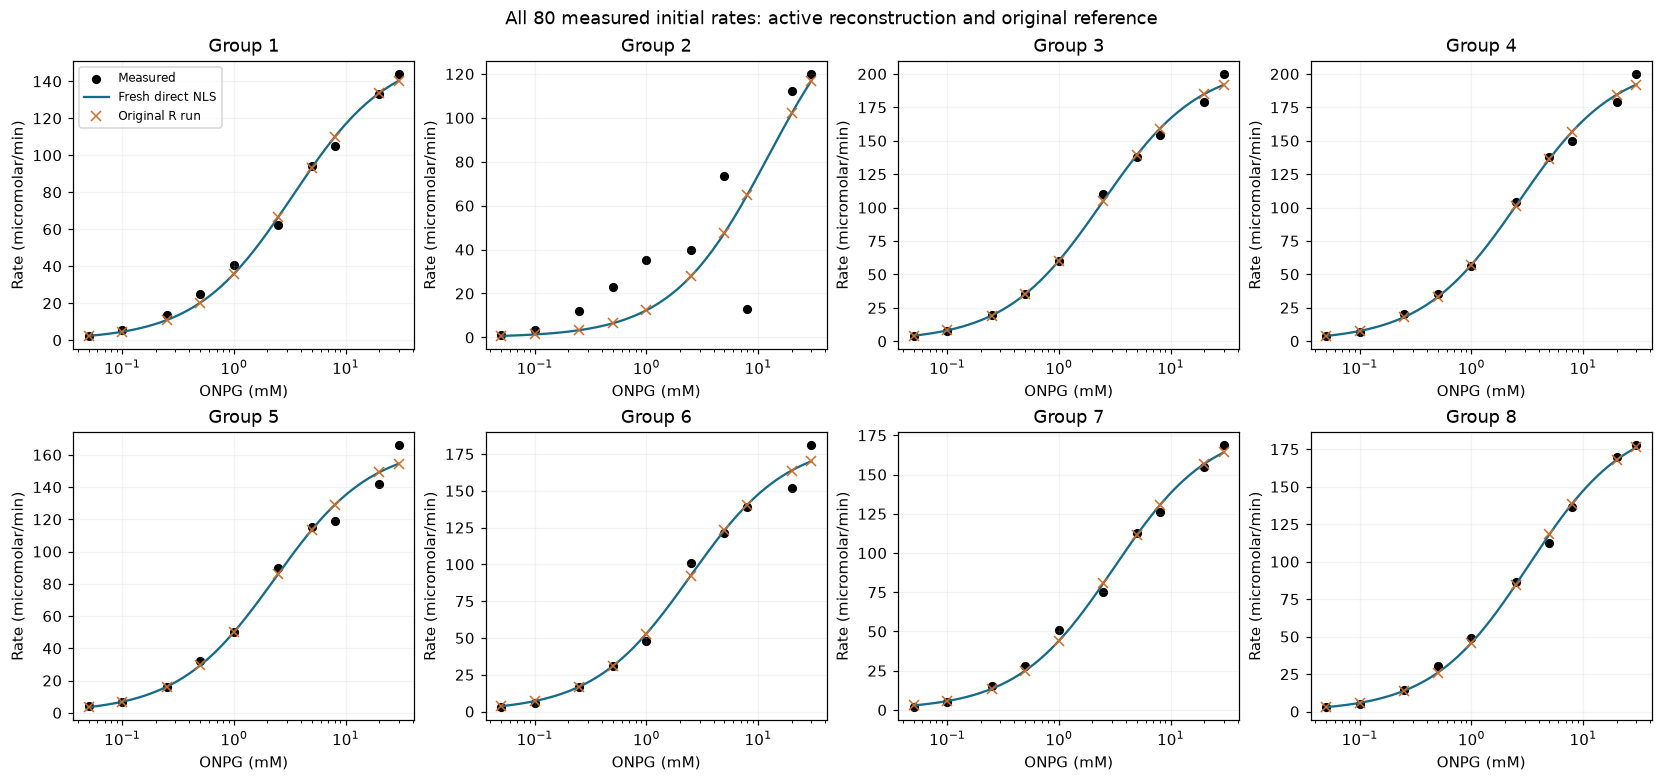

In [2]:
start=time.perf_counter()
fresh=reconstruct(s,observed)
full=compare(s,observed,False)
removed=compare(s,observed,True)
corrected=np.array([ecb(s,v,corrected=True) for v in observed])
loo=sensitivity(s,observed)
runtime=time.perf_counter()-start
with np.load('notebooks/reference_outputs/original.npz',allow_pickle=False) as a:
    original={k:a[k].copy() for k in a.files}
primary=np.column_stack((fresh['reconstruction'][0],fresh['maximum_rate'][0]))
Path('output').mkdir(exist_ok=True)
np.savez('output/reconstruction.npz',**fresh)
report,exitcode=judge.evaluate('output/reconstruction.npz')
assert exitcode==0,report
Path('output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8')
np.savez('notebooks/reference_outputs/fresh.npz',parameters=np.array([full,removed]),corrected_ecb=corrected,leave_one_out=loo,**fresh)
print(f'Full active reconstruction, 96 method/scenario fits and 80 sensitivity fits: {runtime:.4f} s')
print('Sensitivity failed coordinate entries:',np.count_nonzero(~np.isfinite(loo)))
show(vis.observations(s,observed,primary,original['parameters'][0,0]))


## 3. Physics

For substrate concentration $s_i$ and one experimental group, the model is
$$f_i(K,V)=V\frac{s_i}{K+s_i},\qquad y_i=f_i(K,V)+\epsilon_i.$$
Here $y_i$ is the observed initial rate; $K$ is the Michaelis concentration(mM), $V$ is the maximum rate(micromolar/min), and $\epsilon_i$ is uncalibrated measurement error. Positive $K,V$ imply zero rate at zero substrate, half-maximum rate at $s_i=K$, and saturation toward $V$ at large substrate.

At low substrate only the ratio $V/K$ is strongly constrained. Observations spanning the transition and high concentrations provide separate information. Missing assay metadata and unexplained errors still limit interpretation. We fit groups separately, with no artificial common-parameter constraint and no prior based on a hidden answer.

The forward Jacobian columns are
$$\frac{\partial f_i}{\partial K}=-\frac{V s_i}{(K+s_i)^2},\qquad\frac{\partial f_i}{\partial V}=\frac{s_i}{K+s_i}.$$
Independent finite-difference tests verify these derivatives and the loss-gradient sign. The original vignette's displayed derivative with respect to $K$ has a sign inconsistency; it is not used as executable physics.

## 4. Method

Direct NLS minimizes the unweighted residual sum of squares
$$E(K,V)=\sum_i r_i^2,\qquad r_i=y_i-f_i(K,V).$$
With Jacobian $J=QR$, residual projection $q=Q^\mathsf{T}r$ and orthogonal remainder $r_\perp=r-Qq$, the local Gauss-Newton step solves
$$R\Delta p=q,\qquad p=(K,V)^\mathsf{T},\qquad p_{\mathrm{new}}=p+\alpha\Delta p.$$
Step length $\alpha$ is halved until RSS does not increase. The original nls relative-offset criterion is $\lVert q\rVert/\lVert r_\perp\rVert\le10^{-5}$, with at most50 updates and minimum step1/1024. Parameters are rounded to three decimals before recomputing predicted rates, exactly as the original reporting convention. Analytic derivatives replace original finite differences; complete original parity is tested independently.

**Known upstream defect, preserved and disclosed.** ECB initializes from pairwise lines $V=m_iK+y_i$, where $m_i=y_i/s_i$. The correct intersection has
$$K_{ij}=\frac{y_j-y_i}{m_i-m_j},\qquad V_{ij}=m_iK_{ij}+y_i.$$
The original code instead uses $y_j$ in the second formula, making a pairwise error $y_j-y_i$ and breaking permutation invariance. We preserve the original median initializer to reproduce the selected direct NLS, and explicitly label its standalone output as a buggy comparison. Corrected geometric ECB is separately recomputed as a diagnostic; it does not replace primary reconstruction.

Other comparisons are ordinary and weighted double-reciprocal regression, Hanes-Woolf and Eadie-Hofstee regression. Weighted double-reciprocal uses inverse fourth powers of the **rounded reciprocal rates**, preserving original conventions. All six methods are evaluated on all eight complete series and on the author group2-deletion scenario. Negative transformed estimates are retained as failures, not clipped or erased.

Method,Maximum original-vs-fresh parameter difference (native units)
Direct NLS,0
LB,0
Weighted LB,0
ECB (upstream bug),0
Hanes-Woolf,0
Eadie-Hofstee,0


Frozen direct prediction tolerance0.002; measured maximum: 4.831690603168681e-13


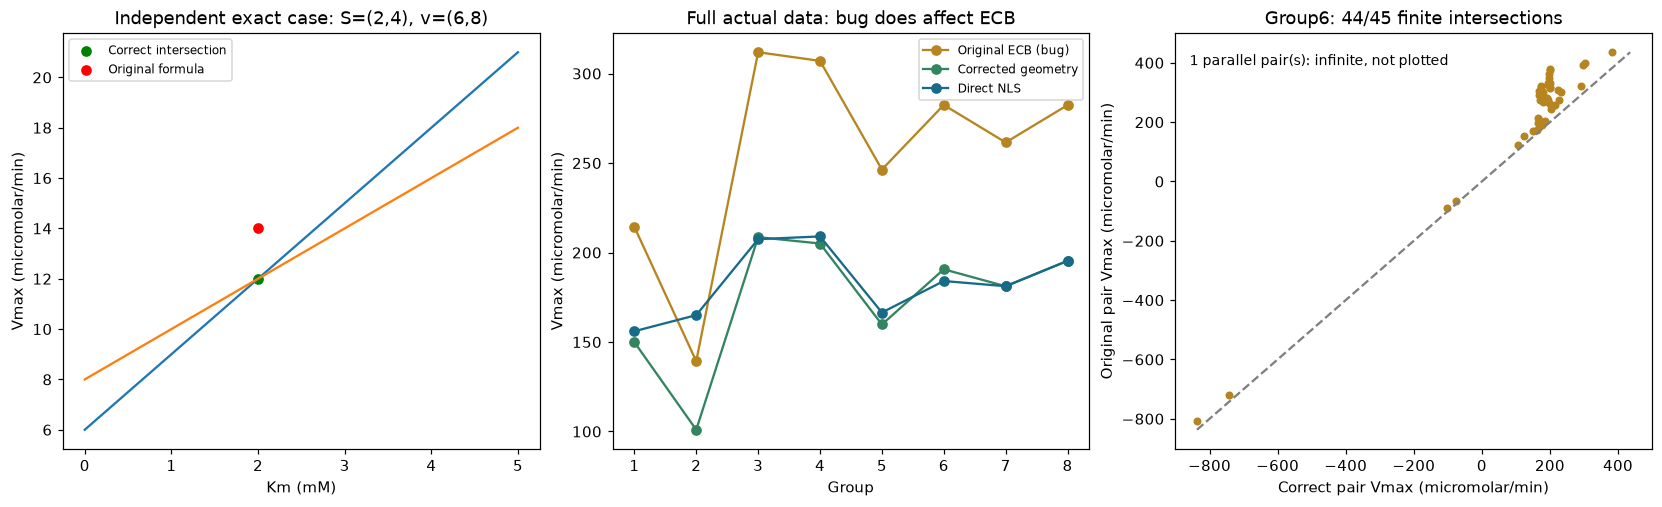

In [3]:
parity=np.max(np.abs(np.array([full,removed])-original['parameters']),axis=(0,2,3))
display(HTML('<table><tr><th>Method</th><th>Maximum original-vs-fresh parameter difference (native units)</th></tr>'+''.join(f'<tr><td>{name}</td><td>{value:.12g}</td></tr>' for name,value in zip(vis.LABELS,parity))+'</table>'))
assert parity[0]<=.002 and np.all(parity[1:]<=1e-8)
print('Frozen direct prediction tolerance0.002; measured maximum:',np.max(abs(fresh['fitted_rate'][0]-original['fitted'])))
assert np.max(abs(fresh['fitted_rate'][0]-original['fitted']))<=.002
show(vis.ecb_diagnostic(s,observed,full,corrected))


## 5. Results

### All experimental groups and all original methods

The next panels report the inferred physical parameters, actual observation residuals and the paper's group6 comparison. Original and fresh numeric parity is a separate question from observed-rate fit quality. Particularly, weighted reciprocal regression is not identical to unweighted direct least squares; its objective and rounding conventions differ. The flawed ECB result is not a valid physical standard even though it can be reproduced exactly.

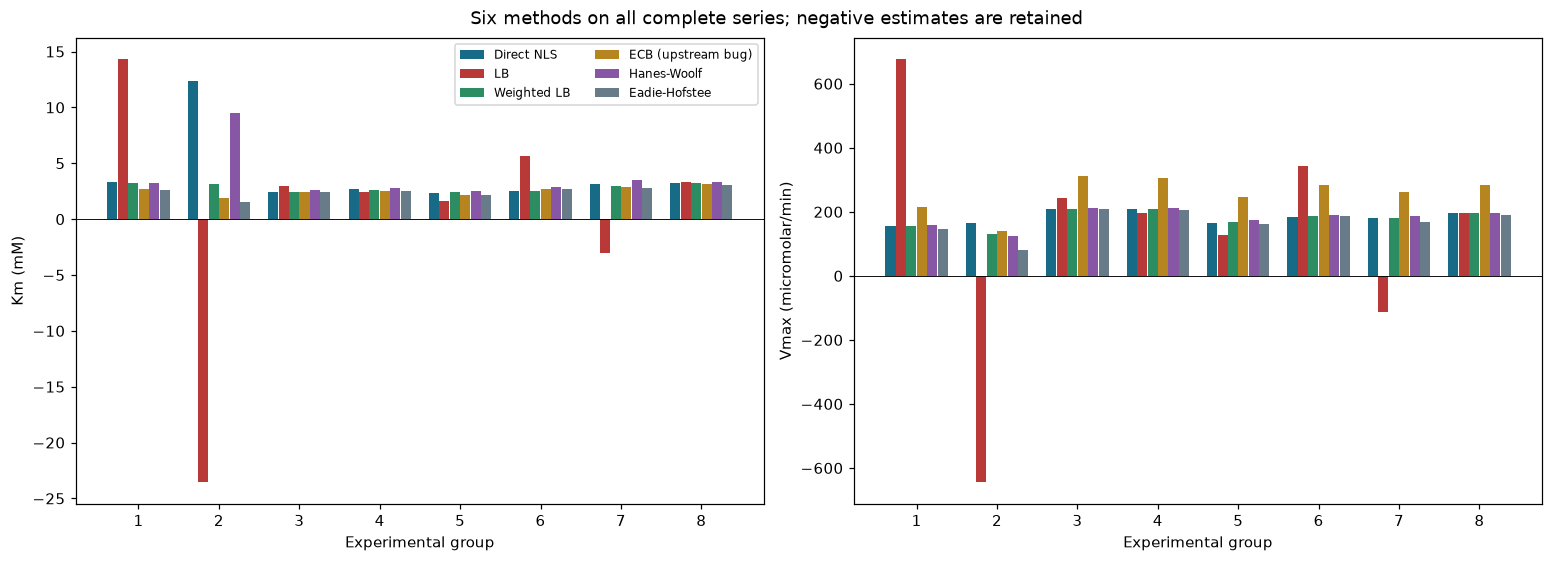

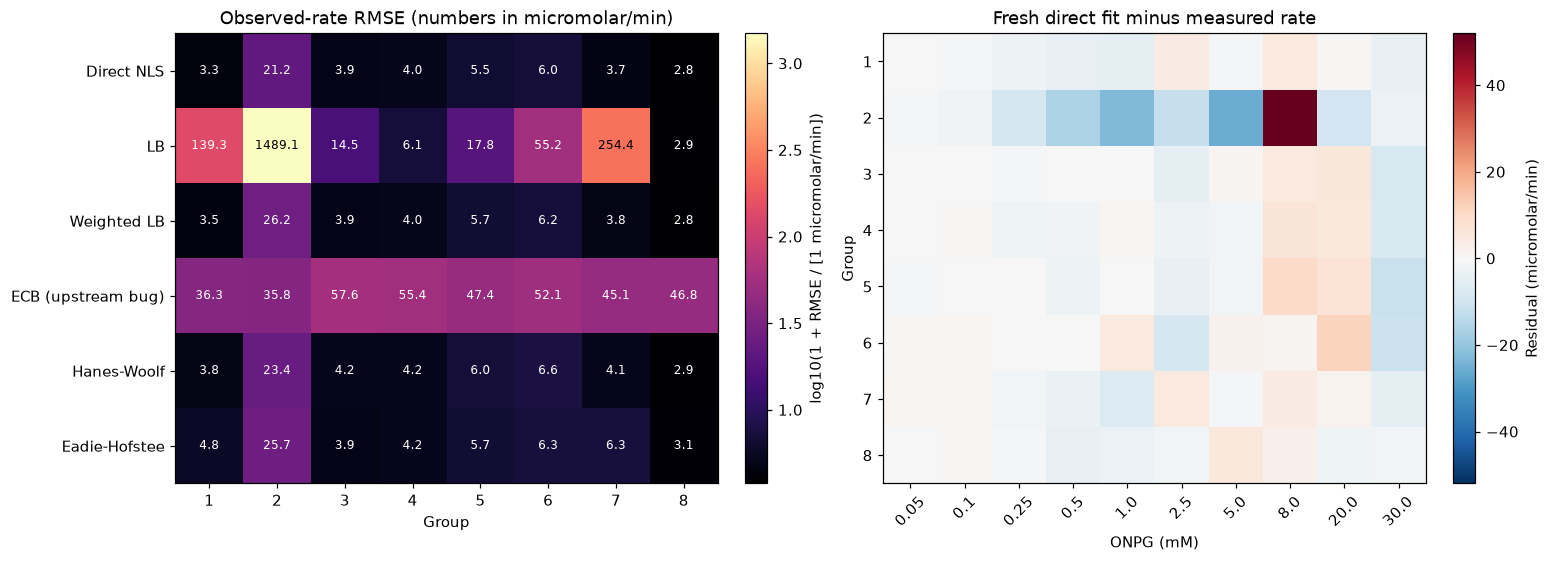

Negative or zero parameter counts per method: {'direct': 0, 'lb': 4, 'weighted_lb': 0, 'ecb': 0, 'hw': 0, 'eh': 0}


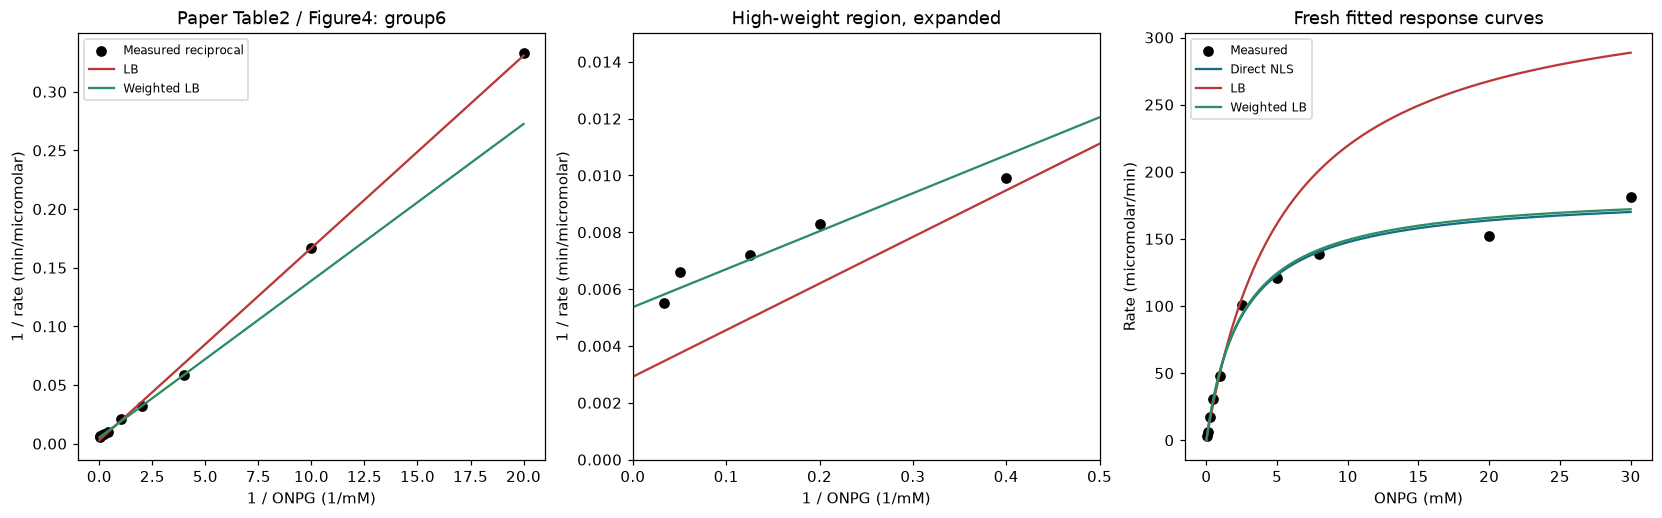

Group6 published comparison reproduced: rows direct,LB,weightedLB; columns Km(mM), Vmax(micromolar/min)
[[  2.479 184.073]
 [  5.62  342.76 ]
 [  2.49  186.37 ]]


In [4]:
show(vis.parameters(full))
fig,rmse=vis.errors(s,observed,full)
show(fig)
print('Negative or zero parameter counts per method:',dict(zip(METHODS,np.sum(full<=0,axis=(1,2)).tolist())))
show(vis.paper_comparison(s,observed,full))
print('Group6 published comparison reproduced: rows direct,LB,weightedLB; columns Km(mM), Vmax(micromolar/min)')
print(full[:3,5])


### Author outlier removal, without concealing the complete-data result

The author vignette removes the group2 observation at8mM. Our primary binding retains it; the next comparison actively reproduces the deletion as a separate, fully labeled experiment, for all six methods. This is a large scientific sensitivity, not numerical solver instability. The remaining seven groups are also rerun in the deletion scenario and must remain unchanged.

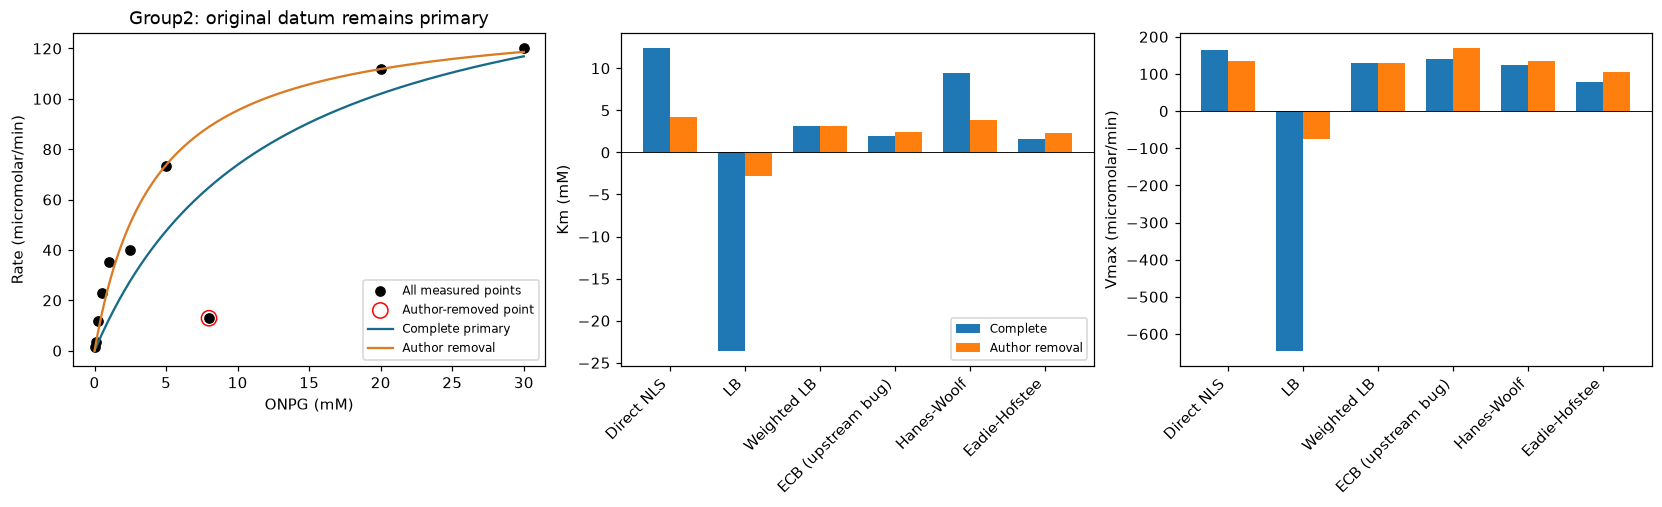

Group2 primary direct: [ 12.352 165.018] ; author-deletion direct: [  4.162 135.114]
Group2 parameter ratios deletion/complete: [0.33694948 0.81878341]


In [5]:
show(vis.deletion(s,observed,full,removed))
np.testing.assert_array_equal(full[:,[0,2,3,4,5,6,7]],removed[:,[0,2,3,4,5,6,7]])
print('Group2 primary direct:',full[0,1],'; author-deletion direct:',removed[0,1])
print('Group2 parameter ratios deletion/complete:',removed[0,1]/full[0,1])


### Identifiability and uncertainty

For a fixed positive $K$, define $a_i=s_i/(K+s_i)$. Eliminate the linear parameter exactly:
$$V(K)=\frac{\sum_i a_i y_i}{\sum_i a_i^2},\qquad E_{\mathrm{profile}}(K)=\sum_i\bigl(y_i-V(K)a_i\bigr)^2.$$
These profiles show how well the actual data distinguish positive saturation constants. They are not Bayesian posteriors or calibrated confidence limits. The original unrestricted NLS can reach negative-$K$ high-RSS rational branches from some remote starts; original selected ECB starts converge to the positive solutions displayed here. Native multistart and profile evidence is archived separately.

The sensitivity panel removes each of the80 measured points in turn and refits. Linearized error bars use $\mathrm{Cov}(p)\approx\widehat\sigma^2(J^\mathsf{T}J)^{-1}$, with $\widehat\sigma^2=E/(n-2)$ and $n=10$ observations. They assume independent equal-variance residuals and local linearity; they do not account for assay calibration or model mismatch. This is an explicitly approximate uncertainty diagnostic, not independently known truth.

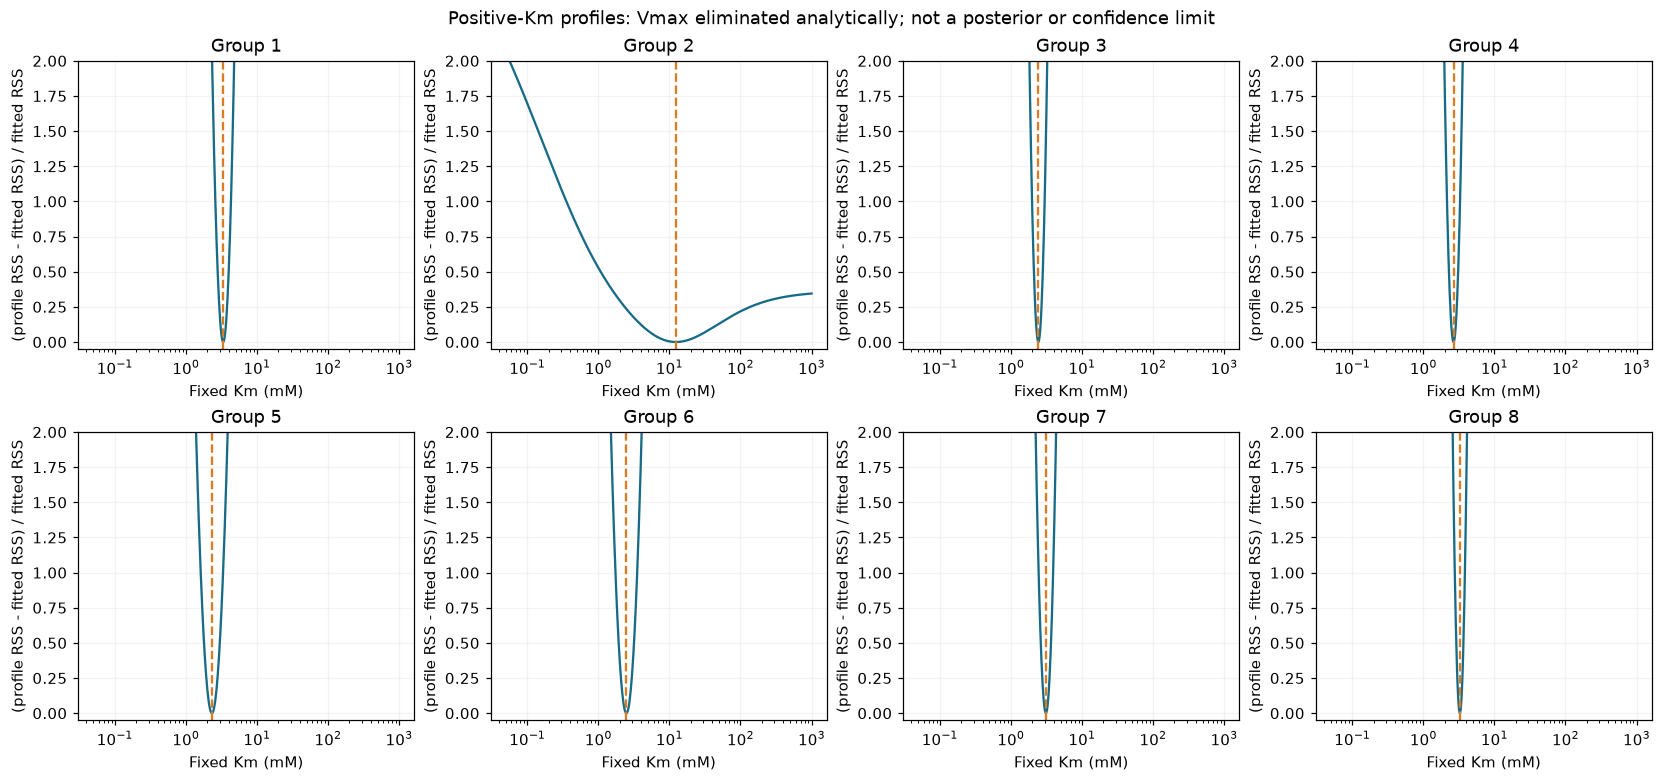

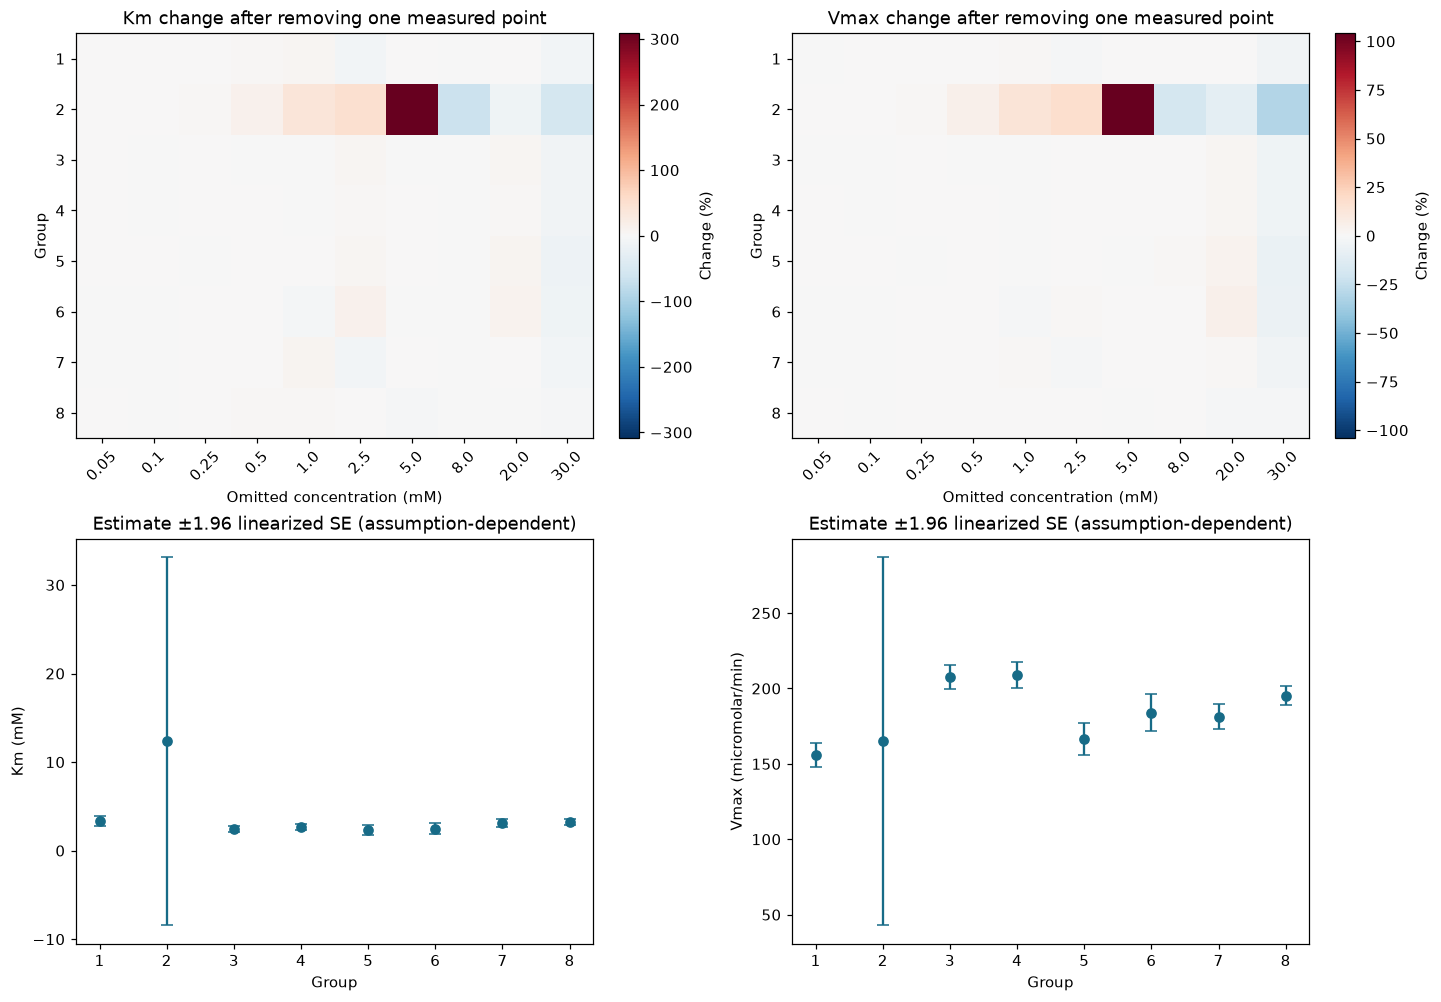

Group,Km(mM),Approx.SE,Vmax(micromolar/min),Approx.SE,Observed RMSE,Scaled Jacobian condition
1,3.355,0.287,156.013,3.953,3.330,6.186
2,12.352,10.601,165.018,62.252,21.207,7.535
3,2.440,0.173,207.449,4.026,3.921,6.169
4,2.661,0.195,208.997,4.273,4.007,6.171
5,2.328,0.288,166.474,5.563,5.527,6.169
6,2.479,0.307,184.073,6.246,6.042,6.169
7,3.115,0.249,181.182,4.208,3.673,6.178
8,3.265,0.184,195.345,3.236,2.762,6.183


Standalone Judge: {
  "status": "pass",
  "passed": true,
  "metrics": {
    "Km_max_relative_error": 0.0,
    "Vmax_max_relative_error": 0.0,
    "fitted_rate_max_absolute_error": 4.831690603168681e-13,
    "output_forward_consistency_max_absolute_error": 0.0
  },
  "thresholds": {
    "Km_max_relative_error": {
      "comparison": "<=",
      "boundary": 0.002
    },
    "Vmax_max_relative_error": {
      "comparison": "<=",
      "boundary": 0.002
    },
    "fitted_rate_max_absolute_error": {
      "comparison": "<=",
      "boundary": 0.1
    },
    "output_forward_consistency_max_absolute_error": {
      "comparison": "<=",
      "boundary": 1e-08
    }
  },
  "errors": []
}


In [6]:
show(vis.profiles(s,observed,primary))
fig,se,condition=vis.sensitivity_plot(s,observed,primary,loo)
show(fig)
rows=''.join(f'<tr><td>{g+1}</td><td>{primary[g,0]:.3f}</td><td>{se[g,0]:.3f}</td><td>{primary[g,1]:.3f}</td><td>{se[g,1]:.3f}</td><td>{rmse[0,g]:.3f}</td><td>{condition[g]:.3f}</td></tr>' for g in range(8))
display(HTML('<table><tr><th>Group</th><th>Km(mM)</th><th>Approx.SE</th><th>Vmax(micromolar/min)</th><th>Approx.SE</th><th>Observed RMSE</th><th>Scaled Jacobian condition</th></tr>'+rows+'</table>'))
print('Standalone Judge:',json.dumps(report,indent=2))


## 6. Conclusion

All eight complete experimental series were actively reconstructed, and all96 six-method/two-scenario original comparisons were retained. Direct NLS parameters reproduce the original standard method under the frozen tolerance; its output rates also satisfy the forward model. This establishes a reproducible local inverse calculation, not independent biological accuracy.

The measured-data story is less tidy than parity alone: reciprocal fitting yields negative or heavily biased estimates for some groups; the group2 anomaly changes its direct parameter estimates substantially; approximate uncertainty is consequently large there. The original ECB initializer has an independently proven intercept error, preserved only for original execution parity and explicitly contrasted with correct geometry. Corrected ECB is not substituted for the selected method.

Raw optical traces, instrument metadata, enzyme loading and calibrated measurement errors are unavailable. Initial-rate extraction cannot be rechecked and turnover constants cannot be inferred. Negative-$K$ remote-start branches also prevent claiming global unconstrained optimization. The benchmark evaluates a well-defined standard estimator of positive, assay-specific saturation parameters while retaining the evidence that limits their physical interpretation.